# Thu nhập 2010–2014: so sánh có và không điều chỉnh CPI

| Phiên bản | Câu hỏi | Đơn vị |
|---|---|---|
| **Không CPI** | Số tiền thu nhập bình quân đầu người có thay đổi không? | Triệu đồng/người/năm theo giá từng năm |
| **Có CPI** | Thu nhập bình quân đầu người có thay đổi sau điều chỉnh mặt bằng giá tiêu dùng không? | Triệu đồng/người/năm theo giá 2010 |

Cùng dữ liệu, cùng số hộ và cùng kiểm định hai mẫu độc lập, phương sai riêng.
Chỉ đổi cách đo thu nhập. Trình bày toàn mẫu → thành thị–nông thôn → Q1–Q4.
Không đọc năm giữa kỳ; không dùng các kết quả tiêu dùng/tài sản của notebook khác.

### Định nghĩa và điều kiện

Trang xác nhận thu nhập hộ là tổng năm, mẫu các năm coi là độc lập. Mỗi hộ
có một giá trị `income / size`; lấy trung bình các giá trị này với mỗi hộ bằng nhau.
Đây chưa phải trung bình dân số có trọng số khảo sát.

Estimator: trung bình mẫu và chênh lệch hai trung bình — Lecture 4.
Kiểm tra phân phối: Jarque–Bera theo Chap 9 trang 21, thêm độ lệch và ảnh hưởng đuôi.
Suy luận: Chap 7 §7.2.4, không giả sử phương sai bằng nhau; CI theo Lecture 5/Chap 7.
Kết quả là xấp xỉ có điều kiện vào mô hình độc lập và phương sai hữu hạn.

Hai phiên bản dùng cùng hộ; tính độc lập được giả định giữa hai năm, không phải giữa hai phiên bản.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
thu_muc_hien_tai = Path.cwd()
thu_muc_du_an = next(
    folder for folder in [thu_muc_hien_tai, *thu_muc_hien_tai.parents]
    if (folder / 'dataset' / 'VHLSS_2014.xls').exists()
)
duong_dan_excel = thu_muc_du_an / 'dataset' / 'VHLSS_2014.xls'
duong_dan_cpi = thu_muc_du_an / 'bao_cao_vhlss' / 'cpi_2010_2014.csv'
danh_sach_nam = [2010, 2014]
muc_y_nghia = 0.05

cac_bang_nam = []
for nam in danh_sach_nam:
    bang_nam = pd.read_excel(duong_dan_excel, sheet_name=str(nam))
    bang_nam = bang_nam.rename(columns={'inc_head': 'Inc_head'})
    cac_bang_nam.append(bang_nam[['Year', 'income', 'size', 'Inc_head', 'area', 'Quart']])
du_lieu = pd.concat(cac_bang_nam, ignore_index=True)
du_lieu['khu_vuc'] = du_lieu['area'].map({1: 'Thành thị', 2: 'Nông thôn'})

assert du_lieu[['income', 'size', 'Inc_head', 'area', 'Quart']].notna().all().all()
assert du_lieu['income'].gt(0).all() and du_lieu['size'].gt(0).all()
assert np.allclose(du_lieu['income'] / du_lieu['size'], du_lieu['Inc_head'])
assert set(du_lieu['Year']) == {2010, 2014}
assert du_lieu['area'].isin([1, 2]).all()
assert du_lieu['Quart'].isin([1, 2, 3, 4]).all()
display(du_lieu.groupby('Year').size().to_frame('Số hộ'))

,Số hộ
Year,
2010,9399
2014,9398


## 1. Hai phiên bản của cùng thước đo

\[
Y_{it}^{N}=\frac{income_{it}}{size_{it}\times1000},\qquad
Y_{it}^{R}=Y_{it}^{N}\times\frac{100}{CPI_t}.
\]

\(CPI_{2010}=100\), \(CPI_{2014}=143.69\), dùng CPI bình quân năm.
Nguồn đầu vào: Niên giám thống kê 2014 trang in 551, lưu trong CSV của dự án.
Hai phiên bản giống nhau ở năm gốc; năm 2014 bản thực bằng bản danh nghĩa chia 1,4369.

In [2]:
bang_cpi = pd.read_csv(duong_dan_cpi)
bang_cpi = bang_cpi.loc[bang_cpi['nam'].isin(danh_sach_nam)].reset_index(drop=True)
assert bang_cpi['nam'].tolist() == danh_sach_nam
assert np.allclose(bang_cpi['cpi_binh_quan_2010_bang_100'], [100, 143.69])
du_lieu['cpi'] = du_lieu['Year'].map(bang_cpi.set_index('nam')['cpi_binh_quan_2010_bang_100'])
du_lieu['thu_nhap_khong_CPI'] = du_lieu['income'] / du_lieu['size'] / 1000
du_lieu['thu_nhap_co_CPI'] = du_lieu['thu_nhap_khong_CPI'] * 100 / du_lieu['cpi']
cac_phien_ban = {
    'Không CPI — giá hiện hành': 'thu_nhap_khong_CPI',
    'Có CPI — giá năm 2010': 'thu_nhap_co_CPI',
}
display(bang_cpi)
display(du_lieu.groupby('Year')[list(cac_phien_ban.values())].agg(['count', 'mean', 'median', 'var']))

,nam,cpi_binh_quan_2010_bang_100
0,2010,100.0000
1,2014,143.6900


thu_nhap_khong_CPI                            thu_nhap_co_CPI          \
                  count    mean  median        var           count    mean   
Year                                                                         
2010               9399 18.2571 13.1675 1,286.3879            9399 18.2571   
2014               9398 29.9747 23.6102   842.1124            9398 20.8607   

                         
      median        var  
Year                     
2010 13.1675 1,286.3879  
2014 16.4313   407.8655

## 2. Kiểm tra phân phối trước khi suy luận

Theo Chap 9: \(JB=n(g_1^2/6+g_2^2/24)\), \(JB\approx\chi^2_2\) dưới
H₀ phân phối chuẩn. \(g_1,g_2\) tính từ moment trung tâm với mẫu số n.
Hỏi mean nên estimator vẫn là mean; JB bác bỏ chuẩn khiến t/CI được đọc như xấp xỉ.

Nhân mọi giá trị trong một năm với cùng hằng số dương **không đổi skewness,
kurtosis, JB hoặc tỷ lệ SS của ngoại lệ**. CPI thay đổi mean/variance và đơn vị,
không làm phân phối thu nhập bớt lệch.

In [3]:
dong_phan_phoi = []
for ten_phien_ban, ten_cot in cac_phien_ban.items():
    for nam in danh_sach_nam:
        mau = du_lieu.loc[du_lieu['Year'].eq(nam), ten_cot]
        do_lech = mau - mau.mean()
        moment_2 = (do_lech ** 2).mean()
        skew = (do_lech ** 3).mean() / moment_2 ** 1.5
        excess_kurtosis = (do_lech ** 4).mean() / moment_2 ** 2 - 3
        jb = len(mau) * (skew ** 2 / 6 + excess_kurtosis ** 2 / 24)
        dong_phan_phoi.append({
            'phien_ban': ten_phien_ban, 'nam': nam, 'n': len(mau),
            'skew': skew, 'excess_kurtosis': excess_kurtosis, 'JB': jb,
            'bac_bo_chuan_5pct': jb > stats.chi2.ppf(0.95, 2),
            'SS_max_pct': 100 * (do_lech ** 2).max() / (do_lech ** 2).sum(),
        })
        assert np.isclose(jb, stats.jarque_bera(mau).statistic)
bang_phan_phoi = pd.DataFrame(dong_phan_phoi)
display(bang_phan_phoi)

,phien_ban,nam,n,skew,excess_kurtosis,JB,bac_bo_chuan_5pct,SS_max_pct
0,Không CPI — giá hiện hành,2010,9399,56.0014,"4,358.5017","7,444,431,498.7819",True,67.9870
1,Không CPI — giá hiện hành,2014,9398,9.1262,216.9022,"18,553,111.0754",True,11.9766
2,Có CPI — giá năm 2010,2010,9399,56.0014,"4,358.5017","7,444,431,498.7819",True,67.9870
3,Có CPI — giá năm 2010,2014,9398,9.1262,216.9022,"18,553,111.0754",True,11.9766


Thu nhập lệch phải mạnh; năm 2010 có quan sát đóng góp khoảng 68% tổng SS.
Giữ dữ liệu gốc, không xóa ngoại lệ. Cỡ mẫu lớn chưa bảo đảm xấp xỉ hữu hạn mẫu
tốt khi một hộ ảnh hưởng mạnh; cả hai phiên bản phải giữ giới hạn này.

### Kiểm tra phân phối riêng cho các nhóm

CPI không đổi chuẩn hóa phân phối **trong từng nhóm và năm**; bảng dưới
kiểm tra phiên bản giá hiện hành, kết quả skew/JB tương tự bản CPI. CI các nhóm
chỉ là xấp xỉ. Đuôi thu nhập nhóm cao nhất năm 2010 vẫn cần đọc thận trọng.

In [4]:
dong_phan_phoi_nhom = []
for ten_pham_vi, cot_nhom, danh_sach_nhom in [
    ('Khu vực', 'khu_vuc', ['Thành thị', 'Nông thôn']),
    ('Quart', 'Quart', [1, 2, 3, 4]),
]:
    for nhom in danh_sach_nhom:
        for nam in danh_sach_nam:
            mask = du_lieu[cot_nhom].eq(nhom) & du_lieu['Year'].eq(nam)
            mau = du_lieu.loc[mask, 'thu_nhap_khong_CPI']
            ss_tung_ho = (mau - mau.mean()) ** 2
            kiem_tra_chuan = stats.jarque_bera(mau)
            dong_phan_phoi_nhom.append({
                'pham_vi': ten_pham_vi, 'nhom': nhom, 'nam': nam, 'n': len(mau),
                'skew': stats.skew(mau, bias=True), 'JB': kiem_tra_chuan.statistic,
                'bac_bo_chuan_5pct': kiem_tra_chuan.pvalue < muc_y_nghia,
                'SS_max_pct': 100 * ss_tung_ho.max() / ss_tung_ho.sum(),
            })
display(pd.DataFrame(dong_phan_phoi_nhom))

,pham_vi,nhom,nam,n,skew,JB,bac_bo_chuan_5pct,SS_max_pct
0,Khu vực,Thành thị,2010,2649,5.7038,"358,094.6933",True,7.5777
1,Khu vực,Thành thị,2014,2781,6.9022,"1,514,903.8333",True,18.2642
2,Khu vực,Nông thôn,2010,6750,62.5702,"5,945,556,407.7567",True,82.4295
3,Khu vực,Nông thôn,2014,6617,12.6593,"45,606,438.2119",True,23.8434
4,Quart,1,2010,2350,-0.3340,111.1139,True,0.3660
5,Quart,1,2014,2352,-0.2145,112.5455,True,0.3087
6,Quart,2,2010,2349,0.0526,129.6188,True,0.1433
7,Quart,2,2014,2350,0.0432,140.8358,True,0.1304
8,Quart,3,2010,2350,0.2524,154.1739,True,0.1550
9,Quart,3,2014,2347,0.1854,133.3834,True,0.1589


## 3. Cùng phương pháp, hai tham số khác nhau

Với mỗi phiên bản V, \(\Delta_V=E(Y_{2014}^V)-E(Y_{2010}^V)\), estimator
\(\widehat\Delta_V=\bar Y_{2014}^V-\bar Y_{2010}^V\).
Kiểm định hai phía: \(H_0:\Delta_V=0\), \(H_1:\Delta_V\ne0\), α = 5%.

Chap 7 §7.2.4:
\[
SE=\sqrt{s_{14}^2/n_{14}+s_{10}^2/n_{10}},\quad T=\widehat\Delta/SE,
\]
\[
\nu=\frac{(s_{14}^2/n_{14}+s_{10}^2/n_{10})^2}
{(s_{14}^2/n_{14})^2/(n_{14}-1)+(s_{10}^2/n_{10})^2/(n_{10}-1)}.
\]
Dùng \(T\approx t_\nu\); bác bỏ khi \(|T|>t_{\nu,0.975}\).
CI 95%: \(\widehat\Delta\pm t_{\nu,0.975}SE\).
Tốc độ tăng \(100(\bar Y_{14}/\bar Y_{10}-1)\) là mô tả, chưa có CI riêng cho tỷ lệ tăng.

In [5]:
def so_sanh_thu_nhap(mau_2010, mau_2014):
    """Tính thay đổi 2014 − 2010, dùng hai phương sai riêng."""
    mau_2010 = pd.Series(mau_2010).dropna()
    mau_2014 = pd.Series(mau_2014).dropna()
    so_ho_2010, so_ho_2014 = len(mau_2010), len(mau_2014)
    trung_binh_2010, trung_binh_2014 = mau_2010.mean(), mau_2014.mean()
    thanh_phan_2010 = mau_2010.var(ddof=1) / so_ho_2010
    thanh_phan_2014 = mau_2014.var(ddof=1) / so_ho_2014
    sai_so_chuan = np.sqrt(thanh_phan_2010 + thanh_phan_2014)
    bac_tu_do = (thanh_phan_2010 + thanh_phan_2014) ** 2 / (
        thanh_phan_2010 ** 2 / (so_ho_2010 - 1)
        + thanh_phan_2014 ** 2 / (so_ho_2014 - 1)
    )
    chenh_lech = trung_binh_2014 - trung_binh_2010
    thong_ke_t = chenh_lech / sai_so_chuan
    nguong_t = stats.t.ppf(1 - muc_y_nghia / 2, bac_tu_do)
    sai_so_bien = nguong_t * sai_so_chuan
    return pd.Series({
        'n_2010': so_ho_2010, 'n_2014': so_ho_2014,
        'TB_2010': trung_binh_2010, 'TB_2014': trung_binh_2014,
        'chenh_lech': chenh_lech, 'tang_pct': 100 * (trung_binh_2014 / trung_binh_2010 - 1),
        'SE': sai_so_chuan, 'df': bac_tu_do, 't': thong_ke_t,
        'p_value': 2 * stats.t.sf(abs(thong_ke_t), bac_tu_do),
        'CI95_duoi': chenh_lech - sai_so_bien,
        'CI95_tren': chenh_lech + sai_so_bien,
    })

ket_qua_toan_mau = {}
cac_cap_doi_chieu = []
for ten_phien_ban, ten_cot in cac_phien_ban.items():
    mau_2010 = du_lieu.loc[du_lieu['Year'].eq(2010), ten_cot]
    mau_2014 = du_lieu.loc[du_lieu['Year'].eq(2014), ten_cot]
    ket_qua = so_sanh_thu_nhap(mau_2010, mau_2014)
    ket_qua_toan_mau[ten_phien_ban] = ket_qua
    cac_cap_doi_chieu.append((mau_2010, mau_2014, ket_qua))
bang_so_sanh_chung = pd.DataFrame(ket_qua_toan_mau).T
display(bang_so_sanh_chung[[
    'TB_2010', 'TB_2014', 'chenh_lech', 'tang_pct', 'CI95_duoi', 'CI95_tren', 'p_value'
]].style.format({'p_value': '{:.3e}'}))

,TB_2010,TB_2014,chenh_lech,tang_pct,CI95_duoi,CI95_tren,p_value
Không CPI — giá hiện hành,18.257094,29.974671,11.717577,64.180956,10.784790,12.650364,1.083e-131
Có CPI — giá năm 2010,18.257094,20.860652,2.603558,14.260530,1.771340,3.435777,8.890e-10


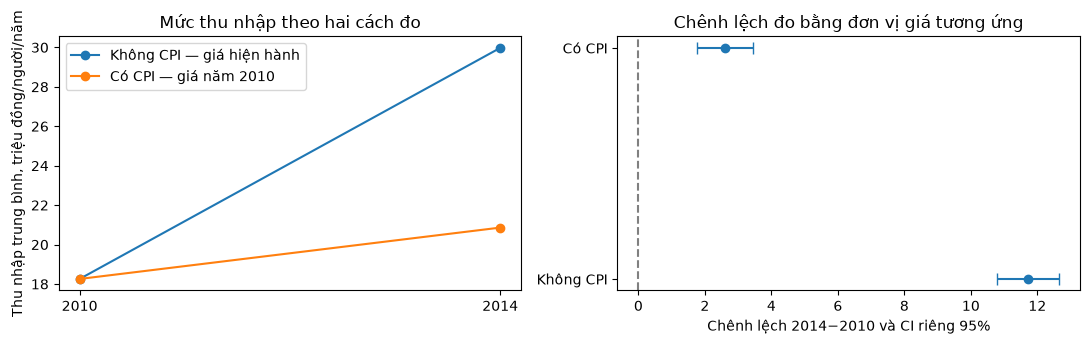

In [6]:
hinh, cac_truc = plt.subplots(1, 2, figsize=(11, 3.5))
for ten_phien_ban, ten_cot in cac_phien_ban.items():
    trung_binh_theo_nam = du_lieu.groupby('Year')[ten_cot].mean()
    cac_truc[0].plot(danh_sach_nam, trung_binh_theo_nam, marker='o', label=ten_phien_ban)
cac_truc[0].set_xticks(danh_sach_nam)
cac_truc[0].set_ylabel('Thu nhập trung bình, triệu đồng/người/năm')
cac_truc[0].set_title('Mức thu nhập theo hai cách đo')
cac_truc[0].legend()

uoc_luong = bang_so_sanh_chung['chenh_lech'].to_numpy()
cac_truc[1].errorbar(
    uoc_luong, [0, 1],
    xerr=[uoc_luong - bang_so_sanh_chung['CI95_duoi'], bang_so_sanh_chung['CI95_tren'] - uoc_luong],
    fmt='o', capsize=4,
)
cac_truc[1].set_yticks([0, 1], ['Không CPI', 'Có CPI'])
cac_truc[1].axvline(0, color='grey', linestyle='--')
cac_truc[1].set_xlabel('Chênh lệch 2014−2010 và CI riêng 95%')
cac_truc[1].set_title('Chênh lệch đo bằng đơn vị giá tương ứng')
plt.tight_layout()
plt.show()

In [7]:
ket_qua_danh_nghia = ket_qua_toan_mau['Không CPI — giá hiện hành']
ket_qua_thuc = ket_qua_toan_mau['Có CPI — giá năm 2010']
display(Markdown(
    f'**Đọc kết quả chung:** Không CPI, thu nhập trung bình '
    f'**{ket_qua_danh_nghia["TB_2010"]:.3f} → {ket_qua_danh_nghia["TB_2014"]:.3f}**, '
    f'tăng **{ket_qua_danh_nghia["tang_pct"]:.2f}%**. '
    f'Có CPI, mức tương ứng **{ket_qua_thuc["TB_2010"]:.3f} → '
    f'{ket_qua_thuc["TB_2014"]:.3f}**, tăng **{ket_qua_thuc["tang_pct"]:.2f}%**. '
    'Cả hai CI chênh lệch nằm phía dương theo xấp xỉ đã nêu. '
    'Mức tăng tiền ghi nhận lớn hơn mức tăng sau điều chỉnh giá; '
    'bản CPI phù hợp với câu hỏi sức mua thu nhập theo rổ tiêu dùng chung.'
))

**Đọc kết quả chung:** Không CPI, thu nhập trung bình **18.257 → 29.975**, tăng **64.18%**. Có CPI, mức tương ứng **18.257 → 20.861**, tăng **14.26%**. Cả hai CI chênh lệch nằm phía dương theo xấp xỉ đã nêu. Mức tăng tiền ghi nhận lớn hơn mức tăng sau điều chỉnh giá; bản CPI phù hợp với câu hỏi sức mua thu nhập theo rổ tiêu dùng chung.

## 4. Thành thị–nông thôn: so sánh trong từng khu vực

Vẫn cùng công thức, tham số là thay đổi thu nhập trong khu vực ở từng cách đo.
Báo CI riêng để so độ lớn; không suy ra mức tăng giữa hai khu vực khác nhau từ
việc các CI riêng có/không chứa 0. CPI chung chưa sửa chênh lệch giá sinh hoạt khu vực.

In [8]:
dong_khu_vuc = []
for khu_vuc in ['Thành thị', 'Nông thôn']:
    for ten_phien_ban, ten_cot in cac_phien_ban.items():
        mau_2010 = du_lieu.loc[du_lieu['khu_vuc'].eq(khu_vuc) & du_lieu['Year'].eq(2010), ten_cot]
        mau_2014 = du_lieu.loc[du_lieu['khu_vuc'].eq(khu_vuc) & du_lieu['Year'].eq(2014), ten_cot]
        ket_qua = so_sanh_thu_nhap(mau_2010, mau_2014)
        dong_khu_vuc.append({'khu_vuc': khu_vuc, 'phien_ban': ten_phien_ban, **ket_qua.to_dict()})
        cac_cap_doi_chieu.append((mau_2010, mau_2014, ket_qua))
bang_so_sanh_khu_vuc = pd.DataFrame(dong_khu_vuc)
display(bang_so_sanh_khu_vuc[[
    'khu_vuc', 'phien_ban', 'n_2010', 'n_2014', 'TB_2010', 'TB_2014',
    'tang_pct', 'chenh_lech', 'CI95_duoi', 'CI95_tren'
]])

,khu_vuc,phien_ban,n_2010,n_2014,TB_2010,TB_2014,tang_pct,chenh_lech,CI95_duoi,CI95_tren
0,Thành thị,Không CPI — giá hiện hành,"2,649.0000","2,781.0000",27.0885,42.4351,56.6533,15.3465,13.7275,16.9656
1,Thành thị,Có CPI — giá năm 2010,"2,649.0000","2,781.0000",27.0885,29.5324,9.0217,2.4438,1.1097,3.7780
2,Nông thôn,Không CPI — giá hiện hành,"6,750.0000","6,617.0000",14.7913,24.7378,67.2462,9.9466,8.8531,11.0400
3,Nông thôn,Có CPI — giá năm 2010,"6,750.0000","6,617.0000",14.7913,17.2161,16.3938,2.4248,1.4179,3.4318


## 5. Q1–Q4: so sánh cùng nhãn nhóm ở hai thời điểm

Giữ `Quart` gốc, không chia lại nhóm. Nhãn tương ứng từng năm, không phải cùng
hộ qua thời gian. CI điều kiện theo nhãn cung cấp, chưa tính bất định điểm cắt.
Điều chỉnh CPI chung trong một năm không đổi thứ tự thu nhập hay nhãn nhóm.
Không kiểm định thu nhập Q1 khác Q4 như một phát hiện vì thu nhập dùng để xếp nhóm.

In [9]:
dong_quart = []
for quart in [1, 2, 3, 4]:
    for ten_phien_ban, ten_cot in cac_phien_ban.items():
        mau_2010 = du_lieu.loc[du_lieu['Quart'].eq(quart) & du_lieu['Year'].eq(2010), ten_cot]
        mau_2014 = du_lieu.loc[du_lieu['Quart'].eq(quart) & du_lieu['Year'].eq(2014), ten_cot]
        ket_qua = so_sanh_thu_nhap(mau_2010, mau_2014)
        dong_quart.append({'Quart': quart, 'phien_ban': ten_phien_ban, **ket_qua.to_dict()})
        cac_cap_doi_chieu.append((mau_2010, mau_2014, ket_qua))
bang_so_sanh_quart = pd.DataFrame(dong_quart)
display(bang_so_sanh_quart[[
    'Quart', 'phien_ban', 'n_2010', 'n_2014', 'TB_2010', 'TB_2014',
    'tang_pct', 'chenh_lech', 'CI95_duoi', 'CI95_tren'
]])

,Quart,phien_ban,n_2010,n_2014,TB_2010,TB_2014,tang_pct,chenh_lech,CI95_duoi,CI95_tren
0,1,Không CPI — giá hiện hành,"2,350.0000","2,352.0000",5.2568,9.0409,71.9850,3.7841,3.6500,3.9182
1,1,Có CPI — giá năm 2010,"2,350.0000","2,352.0000",5.2568,6.2919,19.6917,1.0351,0.9308,1.1395
2,2,Không CPI — giá hiện hành,"2,349.0000","2,350.0000",10.3822,18.7145,80.2549,8.3322,8.2034,8.4611
3,2,Có CPI — giá năm 2010,"2,349.0000","2,350.0000",10.3822,13.0242,25.4471,2.6420,2.5421,2.7419
4,3,Không CPI — giá hiện hành,"2,350.0000","2,347.0000",17.0929,29.8271,74.4996,12.7342,12.5464,12.9220
5,3,Có CPI — giá năm 2010,"2,350.0000","2,347.0000",17.0929,20.7580,21.4417,3.6650,3.5144,3.8157
6,4,Không CPI — giá hiện hành,"2,350.0000","2,349.0000",40.2931,62.3477,54.7353,22.0546,18.8849,25.2242
7,4,Có CPI — giá năm 2010,"2,350.0000","2,349.0000",40.2931,43.3904,7.6869,3.0973,0.1660,6.0286


## 6. Kiểm tra số học và điều chỉnh giá

Đối chiếu công thức t/df/CI với SciPy trên cả 14 cặp so sánh; kiểm tra CPI chỉ
đổi thang đo trong năm và giữ đúng nhãn/mẫu. Không ép kết quả phải tăng hay có ý nghĩa.

In [10]:
for mau_2010, mau_2014, ket_qua in cac_cap_doi_chieu:
    tham_chieu = stats.ttest_ind(mau_2014, mau_2010, equal_var=False)
    ci = tham_chieu.confidence_interval(confidence_level=0.95)
    assert np.allclose([ket_qua['t'], ket_qua['df']], [tham_chieu.statistic, tham_chieu.df])
    assert np.isclose(ket_qua['p_value'], tham_chieu.pvalue, rtol=1e-10, atol=0)
    assert np.allclose([ket_qua['CI95_duoi'], ket_qua['CI95_tren']], [ci.low, ci.high])

for nam in danh_sach_nam:
    mau_khong_CPI = du_lieu.loc[du_lieu['Year'].eq(nam), 'thu_nhap_khong_CPI']
    mau_co_CPI = du_lieu.loc[du_lieu['Year'].eq(nam), 'thu_nhap_co_CPI']
    he_so_gia = 100 / bang_cpi.loc[bang_cpi['nam'].eq(nam), 'cpi_binh_quan_2010_bang_100'].iloc[0]
    assert np.allclose(mau_co_CPI, mau_khong_CPI * he_so_gia)
    assert np.isclose(mau_co_CPI.mean(), mau_khong_CPI.mean() * he_so_gia)
    assert np.isclose(mau_co_CPI.var(ddof=1), mau_khong_CPI.var(ddof=1) * he_so_gia ** 2)
    assert np.isclose(stats.jarque_bera(mau_co_CPI).statistic, stats.jarque_bera(mau_khong_CPI).statistic)

assert len(cac_cap_doi_chieu) == 14
assert du_lieu.groupby('Year').size().tolist() == [9399, 9398]
print('14 cặp t/CI, công thức giá, mẫu số và tính bất biến phân phối: khớp.')

14 cặp t/CI, công thức giá, mẫu số và tính bất biến phân phối: khớp.


### Đọc hai phiên bản để trả lời đúng câu hỏi

- Bản **không CPI** trả lời thay đổi số tiền thu nhập ghi nhận.
- Bản **có CPI** trả lời thay đổi thu nhập sau điều chỉnh giá theo CPI chung.
- Hai bản có mục tiêu khác nhau; không coi mức tăng danh nghĩa là mức tăng sức mua.
- Suy luận chưa có trọng số/thiết kế khảo sát; CI riêng không có bảo đảm đồng thời.
  CPI chung chưa mô tả rổ mua sắm từng nhóm; đuôi thu nhập vẫn ảnh hưởng mạnh.

**Ghi chú khi so sánh:**